In [1]:
import json
import torch, pickle
from data_utils import *

In [2]:
tr_data = json.load(open("/data/user_data/sjaiswa3/iprm_datasets/star_data/STAR_train.json",'rb'))
val_data = json.load(open("/data/user_data/sjaiswa3/iprm_datasets/star_data/STAR_val.json",'rb'))
test_data = json.load(open("/data/user_data/sjaiswa3/iprm_datasets/star_data/STAR_test.json",'rb'))
objs_bbox = pickle.load(open("/data/user_data/sjaiswa3/iprm_datasets/star_data/object_bbox_and_relationship.pkl",'rb'))
person_bbox = pickle.load(open("/data/user_data/sjaiswa3/iprm_datasets/star_data/person_bbox.pkl",'rb'))

In [8]:
from tqdm import tqdm

obj_bboxes_by_videoid = {}
for i, (video_and_frame_id, item) in enumerate(tqdm(objs_bbox.items(), desc="Processing object bboxes")):
    #print(video_and_frame_id.split('/'))
    
    video_id, frame_id = video_and_frame_id.split('/')[0], video_and_frame_id.split('/')[1]
    if(video_id not in obj_bboxes_by_videoid):
        obj_bboxes_by_videoid[video_id] = {'frames':{}, 'vid_info':{'resolution':None, 'num_total_frames':None, 'num_salient_frames':None}}
        video_frame_size = get_video_frame_size(f"/data/user_data/sjaiswa3/iprm_datasets/star_data/Charades_v1_480/{video_id}")
        obj_bboxes_by_videoid[video_id]['vid_info']['resolution'] = video_frame_size
    
    obj_bboxes_by_videoid[video_id]['frames'][frame_id] = item
    
max_num_salient_frames = 0
num_salient_frame_distrb = {}
for vid_id, item in obj_bboxes_by_videoid.items():
    num_salient_frames = obj_bboxes_by_videoid[vid_id]['vid_info']['num_salient_frames'] = len(obj_bboxes_by_videoid[vid_id]['frames'])
    max_num_salient_frames = max(max_num_salient_frames, num_salient_frames)
    if(num_salient_frames not in num_salient_frame_distrb):
        num_salient_frame_distrb[num_salient_frames] = 0
    num_salient_frame_distrb[num_salient_frames]+=1
    
person_bboxes_by_videoid = {}
for i, (video_and_frame_id, item) in enumerate(tqdm(person_bbox.items(), desc="Processing person bboxes")):
    #print(video_and_frame_id.split('/'))
    
    video_id, frame_id = video_and_frame_id.split('/')[0], video_and_frame_id.split('/')[1]
    if(video_id not in person_bboxes_by_videoid):
        person_bboxes_by_videoid[video_id] = {'frames':{}, 'vid_info':{'resolution':None, 'num_total_frames':None, 'num_salient_frames':None}}
        video_frame_size = get_video_frame_size(f"/data/user_data/sjaiswa3/iprm_datasets/star_data/Charades_v1_480/{video_id}")
        person_bboxes_by_videoid[video_id]['vid_info']['resolution'] = video_frame_size
        
    
    person_bboxes_by_videoid[video_id]['frames'][frame_id] = item

num_salient_frame_distrb_sorted = sorted(num_salient_frame_distrb.items(), key=lambda x:x[1], reverse=True)#, max_num_salient_frames

pickle.dump(obj_bboxes_by_videoid, open("/data/user_data/sjaiswa3/iprm_datasets/star_data/obj_bboxes_by_videoid.pkl",'wb'))
pickle.dump(person_bboxes_by_videoid, open("/data/user_data/sjaiswa3/iprm_datasets/star_data/person_bboxes_by_videoid.pkl",'wb'))
json.dump(num_salient_frame_distrb_sorted, open("/data/user_data/sjaiswa3/iprm_datasets/star_data/salient_frame_distrb_sorted.json",'w'))


Processing person bboxes: 100%|██████████| 288782/288782 [00:32<00:00, 8925.98it/s]


In [43]:
person_bboxes_by_videoid['001YG.mp4']

{'frames': {'000089.png': {'bbox': array([[ 24.29774 ,  71.443954, 259.23602 , 268.20288 ]], dtype=float32),
   'bbox_score': array([0.9960979], dtype=float32),
   'bbox_size': (480, 270),
   'bbox_mode': 'xyxy',
   'keypoints': array([[[149.51952 , 120.54931 ,   1.      ],
           [146.48587 , 111.43697 ,   1.      ],
           [141.09274 , 115.824394,   1.      ],
           [111.76759 , 123.58676 ,   1.      ],
           [112.44173 , 124.26174 ,   1.      ],
           [ 82.10537 , 154.6362  ,   1.      ],
           [113.45295 , 168.47343 ,   1.      ],
           [153.56436 , 207.96022 ,   1.      ],
           [162.66527 , 247.44699 ,   1.      ],
           [146.48587 , 149.91127 ,   1.      ],
           [216.59659 , 229.22232 ,   1.      ],
           [112.10466 , 243.73456 ,   1.      ],
           [163.3394  , 267.69662 ,   1.      ],
           [237.83205 , 202.56032 ,   1.      ],
           [239.18031 , 202.56032 ,   1.      ],
           [186.93436 , 219.0975  ,   1

## Some other analysis

In [9]:
x1,y1,x2,y2 = person_bboxes_by_videoid['TJZ0P.mp4']['frames']['000014.png']['bbox'][0]
x1,y1,x2,y2

(np.float32(300.8342),
 np.float32(36.091923),
 np.float32(441.2489),
 np.float32(259.80228))

In [10]:
obj_bboxes_by_videoid['TJZ0P.mp4']['frames']['000014.png']#[0]#['bbox']#.keys() #\

[{'class': 'table',
  'bbox': (97.46428571428572, 172.84523809523813, 222.5, 95.625),
  'attention_relationship': ['unsure'],
  'spatial_relationship': ['in_front_of'],
  'contacting_relationship': ['not_contacting'],
  'metadata': {'tag': 'TJZ0P.mp4/table/000014', 'set': 'test'},
  'visible': True},
 {'class': 'book',
  'bbox': (205.5102813852812,
   168.94462481962464,
   50.85714285714283,
   7.142857142857139),
  'attention_relationship': ['not_looking_at'],
  'spatial_relationship': ['in_front_of'],
  'contacting_relationship': ['not_contacting'],
  'metadata': {'tag': 'TJZ0P.mp4/book/000014', 'set': 'test'},
  'visible': True},
 {'class': 'chair',
  'bbox': (368.0, 131.0, 82.0, 139.0),
  'attention_relationship': ['not_looking_at'],
  'spatial_relationship': ['beneath', 'behind'],
  'contacting_relationship': ['sitting_on', 'leaning_on'],
  'metadata': {'tag': 'TJZ0P.mp4/chair/000014', 'set': 'test'},
  'visible': True},
 {'class': 'paper/notebook',
  'bbox': None,
  'attention_r

In [11]:
tr_data[0]#.keys()

{'question_id': 'Interaction_T1_4',
 'video_id': 'TJZ0P',
 'start': 7.7,
 'end': 15.7,
 'question': 'Which object was eaten by the person?',
 'answer': 'The sandwich.',
 'question_program': [{'function': 'Situations', 'value_input': []},
  {'function': 'Actions', 'value_input': []},
  {'function': 'Filter_Actions_with_Verb', 'value_input': ['eat']},
  {'function': 'Unique', 'value_input': []},
  {'function': 'Query_Objs', 'value_input': []}],
 'choices': [{'choice_id': 0,
   'choice': 'The sandwich.',
   'choice_program': [{'function': 'Equal', 'value_input': ['sandwich']}]},
  {'choice_id': 1,
   'choice': 'The medicine.',
   'choice_program': [{'function': 'Equal', 'value_input': ['medicine']}]},
  {'choice_id': 2,
   'choice': 'The blanket.',
   'choice_program': [{'function': 'Equal', 'value_input': ['blanket']}]},
  {'choice_id': 3,
   'choice': 'The box.',
   'choice_program': [{'function': 'Equal', 'value_input': ['box']}]}],
 'situations': {'000245': {'rel_pairs': [['o000', 'o0

In [12]:
label_vocab = {}
for d in tr_data: 
    label = d['answer']#.split(' ')[-1]
    if(label not in label_vocab):
        label_vocab[label] = [len(label_vocab), 0]
    label_vocab[label][1]+=1

In [13]:
label_vocab

{'The sandwich.': [0, 554],
 'The book.': [1, 1150],
 'The towel.': [2, 664],
 'The bed.': [3, 263],
 'The shoe.': [4, 389],
 'The clothes.': [5, 1297],
 'The blanket.': [6, 635],
 'The phone/camera.': [7, 631],
 'The table.': [8, 532],
 'The closet/cabinet.': [9, 955],
 'The door.': [10, 1333],
 'The dish.': [11, 807],
 'The broom.': [12, 248],
 'The food.': [13, 1072],
 'The cup/glass/bottle.': [14, 1384],
 'The laptop.': [15, 442],
 'The floor.': [16, 178],
 'The bag.': [17, 1055],
 'The picture.': [18, 143],
 'The box.': [19, 704],
 'The sofa/couch.': [20, 283],
 'The refrigerator.': [21, 548],
 'The pillow.': [22, 589],
 'The paper/notebook.': [23, 343],
 'The medicine.': [24, 163],
 'The window.': [25, 118],
 'The mirror.': [26, 10],
 'Took.': [27, 3522],
 'Put down.': [28, 3370],
 'Opened.': [29, 2053],
 'Threw.': [30, 622],
 'Washed.': [31, 73],
 'Tidied up.': [32, 287],
 'Sat at.': [33, 150],
 'Closed.': [34, 1284],
 'Lied on.': [35, 197],
 'Sat on.': [36, 360],
 'Ate.': [37, 

In [14]:
for d in val_data: 
    label = d['answer']#.split(' ')[-1]
    if(label not in label_vocab):
        label_vocab[label] = len(label_vocab)

In [15]:
label_vocab

{'The sandwich.': [0, 554],
 'The book.': [1, 1150],
 'The towel.': [2, 664],
 'The bed.': [3, 263],
 'The shoe.': [4, 389],
 'The clothes.': [5, 1297],
 'The blanket.': [6, 635],
 'The phone/camera.': [7, 631],
 'The table.': [8, 532],
 'The closet/cabinet.': [9, 955],
 'The door.': [10, 1333],
 'The dish.': [11, 807],
 'The broom.': [12, 248],
 'The food.': [13, 1072],
 'The cup/glass/bottle.': [14, 1384],
 'The laptop.': [15, 442],
 'The floor.': [16, 178],
 'The bag.': [17, 1055],
 'The picture.': [18, 143],
 'The box.': [19, 704],
 'The sofa/couch.': [20, 283],
 'The refrigerator.': [21, 548],
 'The pillow.': [22, 589],
 'The paper/notebook.': [23, 343],
 'The medicine.': [24, 163],
 'The window.': [25, 118],
 'The mirror.': [26, 10],
 'Took.': [27, 3522],
 'Put down.': [28, 3370],
 'Opened.': [29, 2053],
 'Threw.': [30, 622],
 'Washed.': [31, 73],
 'Tidied up.': [32, 287],
 'Sat at.': [33, 150],
 'Closed.': [34, 1284],
 'Lied on.': [35, 197],
 'Sat on.': [36, 360],
 'Ate.': [37, 

In [17]:
obj_bboxes_by_videoid['CUZND.mp4']

{'frames': {'000389.png': [{'class': 'light',
    'bbox': (231.45299145299123,
     84.50854700854694,
     6.642327674667513,
     17.307692305782485),
    'attention_relationship': ['looking_at'],
    'spatial_relationship': ['in_front_of'],
    'contacting_relationship': ['holding'],
    'metadata': {'tag': 'CUZND.mp4/light/000389', 'set': 'train'},
    'visible': True},
   {'class': 'phone/camera',
    'bbox': (230.46969696969688,
     83.21212121212125,
     8.181818181818187,
     19.090909090909093),
    'attention_relationship': ['looking_at'],
    'spatial_relationship': ['in_front_of'],
    'contacting_relationship': ['holding'],
    'metadata': {'tag': 'CUZND.mp4/phone_camera/000389', 'set': 'train'},
    'visible': True}],
  '000391.png': [{'class': 'light',
    'bbox': (226.85714285714283,
     75.94289044289039,
     10.379812706804815,
     19.292091800407373),
    'attention_relationship': ['looking_at'],
    'spatial_relationship': ['in_front_of'],
    'contacting_rela

In [18]:
import cv2

def get_video_frame_size(video_file):
    # Open the video file
    cap = cv2.VideoCapture(video_file)

    # Check if the video file was opened successfully
    if not cap.isOpened():
        print("Error: Could not open video file")
        return
    else:
        # Get the frame resolution
        frame_width = int(cap.get(4))  # Width of the frames
        frame_height = int(cap.get(3))  # Height of the frames

        #print(f"Frame resolution: {frame_width}x{frame_height}")

        # Release the video capture object
        cap.release()
        return (frame_width, frame_height)


In [19]:
obj_bboxes_by_videoid['001YG.mp4']

{'frames': {'000264.png': [{'class': 'table',
    'bbox': (217.49999999999986,
     139.97619047619037,
     262.08333333333337,
     100.1214313241892),
    'attention_relationship': ['unsure'],
    'spatial_relationship': ['in_front_of'],
    'contacting_relationship': ['not_contacting'],
    'metadata': {'tag': '001YG.mp4/table/000264', 'set': 'train'},
    'visible': True},
   {'class': 'chair',
    'bbox': (48.00198412698421,
     174.31653069153066,
     193.7229744965878,
     95.68346930846936),
    'attention_relationship': ['not_looking_at'],
    'spatial_relationship': ['beneath', 'behind'],
    'contacting_relationship': ['sitting_on', 'leaning_on'],
    'metadata': {'tag': '001YG.mp4/chair/000264', 'set': 'train'},
    'visible': True}],
  '000093.png': [{'class': 'table',
    'bbox': (221.91847041847052,
     138.15205627705612,
     256.24999999999994,
     120.41666666666666),
    'attention_relationship': ['unsure'],
    'spatial_relationship': ['in_front_of'],
    'co

In [26]:
#video_id = #'001YG'
video_id = '82B2V.mp4'
video_frames = get_video_frames(f"/data/user_data/sjaiswa3/iprm_datasets/star_data/Charades_v1_480/{video_id}")

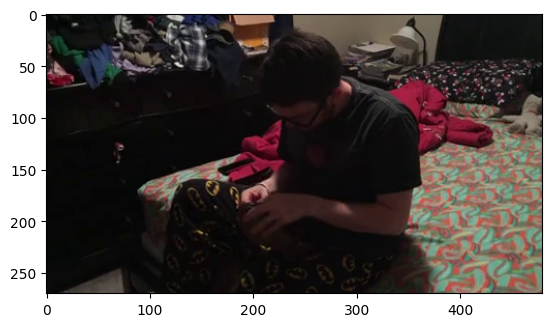

In [27]:
plt.imshow(video_frames[10])

In [28]:
obj_bboxes_by_videoid['001YG.mp4']

{'frames': {'000264.png': [{'class': 'table',
    'bbox': (217.49999999999986,
     139.97619047619037,
     262.08333333333337,
     100.1214313241892),
    'attention_relationship': ['unsure'],
    'spatial_relationship': ['in_front_of'],
    'contacting_relationship': ['not_contacting'],
    'metadata': {'tag': '001YG.mp4/table/000264', 'set': 'train'},
    'visible': True},
   {'class': 'chair',
    'bbox': (48.00198412698421,
     174.31653069153066,
     193.7229744965878,
     95.68346930846936),
    'attention_relationship': ['not_looking_at'],
    'spatial_relationship': ['beneath', 'behind'],
    'contacting_relationship': ['sitting_on', 'leaning_on'],
    'metadata': {'tag': '001YG.mp4/chair/000264', 'set': 'train'},
    'visible': True}],
  '000093.png': [{'class': 'table',
    'bbox': (221.91847041847052,
     138.15205627705612,
     256.24999999999994,
     120.41666666666666),
    'attention_relationship': ['unsure'],
    'spatial_relationship': ['in_front_of'],
    'co

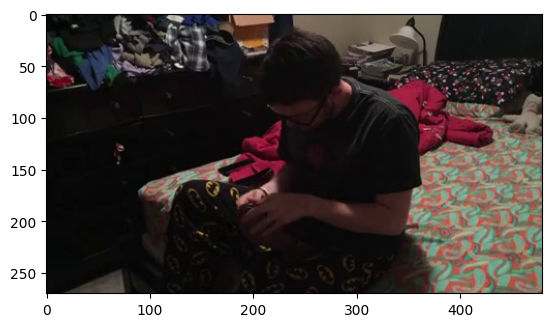

In [33]:
#(0.0, 208.58217967028736, 93.86011805105913, 154.0011610401881)
frame_id = 5
og_img = video_frames[frame_id]
plt.imshow(og_img)

In [35]:
person_bbox['5GK8W.mp4/000044.png']
vidframe_id = '5GK8W.mp4/000044.png'
bboxes = []
try:
    keyframes = person_bbox[vidframe_id]['keypoints'][0]
except:
    keyframes=None
try:
    bboxes.append(('person', list(person_bbox[vidframe_id]['bbox'][0])))
except:
    bboxes = []
vid_id= vidframe_id.split('/')[0].split('.')[0]
frame_id= int(vidframe_id.split('/')[-1].split('.')[0])
video_frames = get_video_frames(f"/data/user_data/sjaiswa3/iprm_datasets/star_data/Charades_v1_480/{vid_id}.mp4")
print(f"num frames: {len(video_frames)}; selected frame id {frame_id}")
og_img = video_frames[frame_id]
for obj in objs_bbox[vidframe_id]:
    #print(obj)
    if(obj['bbox'] is not None):
        bboxes.append((obj['class'], list(obj['bbox'])))


num frames: 2042; selected frame id 44


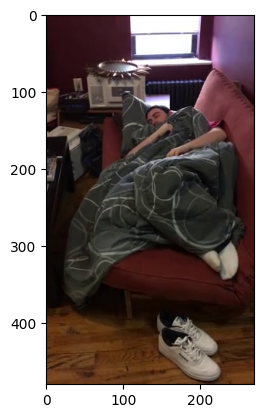

In [36]:
plt.imshow(og_img)

In [37]:
objs_bbox[vidframe_id]

[{'class': 'sofa/couch',
  'bbox': (69.0, 68.0, 201.0, 329.0),
  'attention_relationship': ['not_looking_at'],
  'spatial_relationship': ['behind', 'on_the_side_of'],
  'contacting_relationship': ['lying_on'],
  'metadata': {'tag': '5GK8W.mp4/sofa_couch/000044', 'set': 'train'},
  'visible': True},
 {'class': 'blanket',
  'bbox': (21.770822053439872,
   118.66614433526047,
   224.55532350002767,
   264.09634513095295),
  'attention_relationship': ['not_looking_at'],
  'spatial_relationship': ['in'],
  'contacting_relationship': ['covered_by'],
  'metadata': {'tag': '5GK8W.mp4/blanket/000044', 'set': 'train'},
  'visible': True},
 {'class': 'bed',
  'bbox': (69.83333333333326,
   70.16666666666663,
   200.16666666666674,
   325.8333333333333),
  'attention_relationship': ['not_looking_at'],
  'spatial_relationship': ['behind', 'on_the_side_of'],
  'contacting_relationship': ['lying_on'],
  'metadata': {'tag': '5GK8W.mp4/bed/000044', 'set': 'train'},
  'visible': True}]

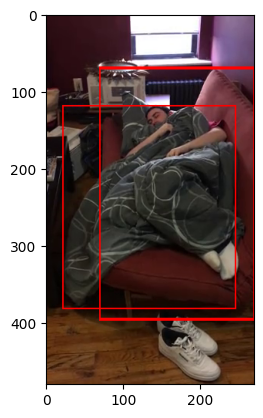

In [38]:
from PIL import Image, ImageDraw
highlight_size = 2
highlight_color = (0, 255, 0)  # Red color in RGB format
    
for item in bboxes:
    bbox=item[1]
    #bbox = [ 10.825662 ,   6.1736574, 122.91022  , 234.68478  ]#obj_info['bbox'].tolist()#[178.9430, 429.4745, 412.0135, 555.8653]
    #print(bbox)
    # Create a drawing context
    draw = ImageDraw.Draw(og_img)
    [x,y,w,h] = bbox
        
    if(item[0] in ['person']): 
        #continue
        
        bbox_coord = bbox#[x, y, x+w, y+h]
        for kframe in keyframes:
            x_k, y_k = kframe[0], kframe[1]
            # Draw a circle at the specified coordinate to highlight the keypoint
            draw.ellipse([(x_k - highlight_size, y_k - highlight_size), (x_k + highlight_size, y_k + highlight_size)], outline=highlight_color, width=2)
            draw.rectangle(bbox_coord, outline="blue", width=2)  # You can customize the outline color and width

    else:
        bbox_coord = [x, y, x+w, y+h]
        draw.rectangle(bbox_coord, outline="red", width=2)  # You can customize the outline color and width

        #print(bbox_coord)
    #print(bbox_coord)
    # Draw a rectangle using the bounding box coordinates
    
    # Define the size and color of the highlight
    
    
#print(row_i)
# Save or display the image with the bounding box
plt.imshow(og_img)#.show() 

In [40]:
bboxes

[('sofa/couch', [69.0, 68.0, 201.0, 329.0]),
 ('blanket',
  [21.770822053439872,
   118.66614433526047,
   224.55532350002767,
   264.09634513095295]),
 ('bed',
  [69.83333333333326,
   70.16666666666663,
   200.16666666666674,
   325.8333333333333])]